# AF3 → HADDOCK EMscoring → OpenMM/CHARMM pipeline

**How to run**
1. Put the AF3 Server results into `AF3_HADDOCK/projects/<DATASET>/input/` — the batch
   zip as downloaded, the extracted batch folder, the sample folders or `fold_NNN` folders.
   (Small files can also be uploaded with the optional upload cell.)
2. Run all cells from the top. The **Registry** cell (1) converts whatever is in `input/`
   into `input/fold_NNN/` every time it runs and builds the sample list from the disk.
3. Another batch later: put it into the same `input/` and run again from the top —
   clashing job numbers are renumbered (batch02 001 → fold_031 …), finished samples are skipped.

```
AF3_HADDOCK/
├── modules/  charmm/                      shared
└── projects/<DATASET>/                    created by you (e.g. ST307)
    ├── input/      fold_001 … fold_NNN    + _raw_imported/ (original uploads), fold_map.csv
    ├── work/       1_structure_pdb … 5_openmm   intermediates (removed by the viewer's cleanup)
    ├── outputs/    pipeline/ viewer/ trajectories/   (kept)
    └── pipeline_status.json
```

| Step | Cell | Reads | Writes |
|---|---|---|---|
| 0 | Setup / Config | – | – |
| 1 | Registry | `input/` | `input/fold_NNN`, `SAMPLES` |
| 2 | Structure preprocessing | AF3 CIF | `work/1_structure_pdb` |
| 3 | AF3 AIR validation | JSON + PDB | `work/2_air` |
| 4 | HADDOCK preparation | PDB | `work/3_haddock_ready` |
| 5 | Evidence records + Kneedle selection | evidence metadata | `OR_CANDIDATE_IDS` |
| 6 | Scoring inputs | `SAMPLES` | `SCORING_INPUTS` |
| 7 | HADDOCK EMscoring | `SCORING_INPUTS` | `work/4_emscoring` |
| 8 | OpenMM + CHARMM | `SCORING_INPUTS` | `work/5_openmm` |
| 9–10 | Merged table, Finalize | – | `outputs/pipeline` |

## 0. Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

# Single install cell. pdbfixer is not on PyPI -> GitHub tag.
!pip install -q gemmi openmm haddock3 https://github.com/openmm/pdbfixer/archive/refs/tags/v1.10.tar.gz

Mounted at /content/drive
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
# ============================================================
# CONFIG  — the only place where paths / switches are defined
# ============================================================
import os
import sys
import importlib
from pathlib import Path

DRIVE      = Path(os.environ.get("AF3_DRIVE_ROOT", "/content/drive/MyDrive"))
MODULE_DIR = DRIVE / "AF3_HADDOCK" / "modules"
if str(MODULE_DIR) not in sys.path:
    sys.path.insert(0, str(MODULE_DIR))

import pipeline_layout as pl
importlib.reload(pl)

# --- project folder ------------------------------------------------------------
# AF3_HADDOCK/projects/<DATASET>/ must exist; put the AF3 results into its input/ folder.
DATASET     = None       # None: the only folder in AF3_HADDOCK/projects/ | or its exact name, e.g. "ST307"
PROJECT_DIR = None       # optional: full path of a project folder elsewhere on Drive

# --- input conversion (done by the Registry cell) ---------------------------------
JOB_OFFSET             = "auto"     # clashing job numbers continue after the highest fold
                                    # (batch02 001 -> fold_031); 0 = keep AF3 numbers; N = +N
INPUT_RAW_AFTER_IMPORT = "archive"  # originals -> input/_raw_imported/ | "delete" | "keep"

_project = pl.resolve_project(DRIVE, DATASET, PROJECT_DIR)
L = pl.make_layout(DRIVE, _project.name, project_dir=_project)
DATASET = L.dataset                      # the folder actually used
L.ensure()
L.input_dir.mkdir(exist_ok=True)
for _w in pl.check_layout(L):
    print("WARNING:", _w)

CHARMM_DIR           = L.charmm_dir
EXTRACTED_DIR        = L.input_dir          # AF3 results (input)
STRUCTURE_OUTPUT_DIR = L.structure_dir
AIR_OUTPUT_DIR       = L.air_dir
HADDOCK_OUTPUT_DIR   = L.haddock_dir
EM_OUTPUT_ROOT       = L.emscoring_dir
OPENMM_ROOT          = L.openmm_dir
OUTPUTS_ROOT         = L.outputs_dir        # final tables (kept after cleanup)

EXPECTED_CHAINS      = ["A", "B"]

# Which PDB is scored by BOTH EMscoring and OpenMM:
#   "structure"     -> MD_output_pdb/fold_xxx/<pdb>           (what v2 actually used)
#   "haddock_ready" -> MD_output_haddock/fold_xxx/*_haddock_ready.pdb
SCORING_INPUT_SOURCE = "structure"

# HADDOCK EMscoring
EM_NCORES          = 2
EM_NEMSTEPS        = 50
HADDOCK_EXECUTABLE = "haddock3"

# OpenMM + CHARMM
#   "forcefield" -> OpenMM bundled charmm36.xml, no PSF needed (uniform for all samples)
#   "psf"        -> CHARMM rtf/prm + PSF from OPENMM_ROOT/psf (samples without PSF fail)
OPENMM_METHOD     = "forcefield"
OPENMM_PLATFORM   = "CUDA"          # falls back to OpenCL/CPU if unusable
OPENMM_MINIMIZE   = True
OPENMM_MAX_ITER   = 500

# DCD trajectory output (written by openmm_charmm_scoring.py, v1.2.0+)
#   frames: initial, minimized, then one frame per OPENMM_REPORT_INTERVAL MD steps
#   OPENMM_MD_STEPS = 0 -> 2-frame minimization DCD only (no MD)
#   MD runs in vacuum (NoCutoff), 1 fs Langevin; it is a short relaxation, not production MD
OPENMM_SAVE_DCD        = True
OPENMM_MD_STEPS        = 0
OPENMM_REPORT_INTERVAL = 1000
OPENMM_TEMPERATURE     = 300.0
CHARMM_TOPOLOGY   = CHARMM_DIR / "top_all36_prot.rtf"
CHARMM_PARAMETER  = CHARMM_DIR / "par_all36m_prot.prm"

def fold_number(fold_id):
    return int(fold_id.split("_")[1])


def fold_of(prediction_id):
    """'fold_004_deguysxt_...' -> 'fold_004'"""
    return str(prediction_id)[:8]


print("pipeline_layout", pl.MODULE_VERSION)
print(L.describe())
if pl.stage_done(L, "cleanup"):
    print("NOTE: intermediates of this dataset were removed by the cleanup cell; "
          "running the pipeline again recomputes every step.")
_folds = pl.detect_folds(EXTRACTED_DIR)[0]
_raw = pl.raw_input_sources(EXTRACTED_DIR)
_n_raw = len(_raw["zips"]) + len(_raw["folders"])
print(f"Input       : {len(_folds)} fold_NNN folder(s)"
      + (f" + {_n_raw} AF3 upload(s) to be converted by the Registry cell" if _n_raw else ""))
if not _folds and not _n_raw:
    print(f"              -> put the AF3 results into {EXTRACTED_DIR}")
print("Scoring PDB :", SCORING_INPUT_SOURCE)
print("OpenMM      :", OPENMM_METHOD, "/", OPENMM_PLATFORM)

### 0b. Optional upload
Only needed to upload small files from this computer; otherwise put the files into `input/` with Google Drive.

In [ ]:
# ============================================================
# OPTIONAL: UPLOAD FROM THIS COMPUTER -> input/
# ============================================================
# For large zips (hundreds of MB) copy them into the input folder with Google
# Drive instead - the browser upload keeps the whole file in memory.
UPLOAD_FROM_COMPUTER = False      # True: shows a file picker under this cell

if UPLOAD_FROM_COMPUTER:
    from google.colab import files
    _uploaded = files.upload()                    # written to the current folder (/content)
    for _name in list(_uploaded):
        _dst = pl.store_upload(Path.cwd() / _name, EXTRACTED_DIR)
        print(f"stored: {_dst}  ({_dst.stat().st_size / 1e6:.1f} MB)")
    del _uploaded
    print("Next: run the Registry cell - it converts the upload into fold_NNN folders.")
else:
    print("Input folder:", EXTRACTED_DIR, "(upload skipped)")

In [3]:
# ============================================================
# ENVIRONMENT CHECK  (no installation here — see Setup)
# ============================================================
import shutil

problems = []

try:
    import openmm
    from openmm import Platform
    names = [Platform.getPlatform(i).getName() for i in range(Platform.getNumPlatforms())]
    print("OpenMM   :", openmm.__version__, names)
except Exception as exc:
    problems.append(f"OpenMM: {exc!r}")

try:
    import pdbfixer
    print("PDBFixer : OK")
except Exception as exc:
    problems.append(f"PDBFixer: {exc!r}")

if shutil.which(HADDOCK_EXECUTABLE):
    print("HADDOCK3 :", shutil.which(HADDOCK_EXECUTABLE))
else:
    problems.append(f"{HADDOCK_EXECUTABLE} executable not found")

if problems:
    raise RuntimeError("Environment check failed:\n  - " + "\n  - ".join(problems))
print("ENVIRONMENT: PASS")

OpenMM   : 8.6.1 ['Reference', 'CPU', 'OpenCL']
PDBFixer : OK
HADDOCK3 : /usr/local/bin/haddock3
ENVIRONMENT: PASS


## 1. Sample registry (converts `input/`, reads the disk)

Builds `SAMPLES` from **what exists on Drive** (AF3 artifacts, structure PDB,
HADDOCK-ready PDB), so the registry is identical after a runtime restart.
The structure PDB is taken from `structure_manifest.json` (the model the
preprocessor actually selected), not from a folder scan.
Missing folds are reported but are not pipeline failures.

In [ ]:
# ============================================================
# SAMPLE REGISTRY (rebuilt from disk every time this cell runs)
# ============================================================
import json

# (a) AF3 uploads in input/ (batch zip, batch folder, sample folders) -> input/fold_NNN/
_imp = pl.import_from_input(EXTRACTED_DIR, offset=JOB_OFFSET, raw_after_import=INPUT_RAW_AFTER_IMPORT)
for _r in _imp["batches"]:
    _new = [f["fold_id"] for f in _r["folds"]]
    if _new or _r["skipped_existing"]:
        print(f"input: {_r['label']}: {len(_new)} new sample(s), offset {_r['offset']}"
              + (f", {_new[0]} ... {_new[-1]}" if _new else "")
              + (f"; already imported: {len(_r['skipped_existing'])}" if _r["skipped_existing"] else ""))
for _m in _imp["moved_raw"]:
    print("  original ->", _m)
if _imp["problems"]:
    raise RuntimeError("AF3 files in input/ could not be converted - nothing was changed:\n  "
                       + "\n  ".join(_imp["problems"]))

# (b) the samples are the fold_NNN folders now in input/
EXPECTED_FOLD_IDS, _ignored = pl.detect_folds(EXTRACTED_DIR)
EXPECTED_FOLD_COUNT = len(EXPECTED_FOLD_IDS)
if _ignored:
    print("WARNING: ignored input folders (need fold_NNN, three digits):", _ignored)
if not EXPECTED_FOLD_IDS:
    raise RuntimeError(
        f"No samples in {EXTRACTED_DIR}.\n"
        "Put the AF3 results there (batch zip, extracted batch folder, sample folders or "
        "fold_NNN folders) and run this cell again."
    )


def structure_pdb_for(structure_dir):
    """
    Structure PDB of one fold.

    Source of truth is structure_manifest.json written by structure_preprocessor
    (status PASS -> pdb.path). Without a manifest, a single *.pdb is accepted;
    several *.pdb without a manifest are ambiguous (stale model) -> None, so the
    fold is re-processed in the next cell and gets a manifest.
    Returns (path or None, note).
    """
    manifest = structure_dir / "structure_manifest.json"
    if manifest.is_file():
        try:
            data = json.loads(manifest.read_text(encoding="utf-8"))
        except Exception:
            data = {}
        if data.get("status") == "PASS":
            p = Path(data.get("pdb", {}).get("path", ""))
            if not p.is_file():                       # Drive mounted elsewhere
                p = structure_dir / p.name
            if p.is_file():
                return p, ""
            return None, f"manifest PDB missing ({p.name})"
        return None, f"manifest status {data.get('status')!r}"

    pdbs = sorted(structure_dir.glob("*.pdb"))
    if len(pdbs) == 1:
        return pdbs[0], "no manifest; single PDB used"
    if len(pdbs) > 1:
        return None, f"no manifest and {len(pdbs)} PDBs {[p.name for p in pdbs]} -> re-process"
    return None, ""

SAMPLES = {}
missing_folds = []
RESOLUTION_FAILURES = []
structure_notes = []

for fold_id in EXPECTED_FOLD_IDS:
    input_dir = EXTRACTED_DIR / fold_id
    if not input_dir.is_dir():
        missing_folds.append(fold_id)
        continue

    try:
        full = sorted(input_dir.glob("*_full_data_0.json"))
        if len(full) != 1:
            raise RuntimeError(f"expected 1 *_full_data_0.json, found {len(full)}")

        summary = sorted(input_dir.glob("*_summary_confidences_0.json"))
        if len(summary) > 1:
            raise RuntimeError(f"{len(summary)} *_summary_confidences_0.json files")

        sample = {
            "fold_id": fold_id,
            "input_dir": input_dir,
            "structure_dir": STRUCTURE_OUTPUT_DIR / fold_id,
            "air_dir": AIR_OUTPUT_DIR / fold_id,
            "haddock_dir": HADDOCK_OUTPUT_DIR / fold_id,
            "full_data_json": full[0],
            "summary_json": summary[0] if summary else None,
            "model_cif_files": sorted(input_dir.glob("*_model_*.cif")),
        }

        # Recover downstream artifacts from disk (manifest first).
        pdb, note = structure_pdb_for(sample["structure_dir"])
        if note:
            structure_notes.append((fold_id, note))
        if pdb is not None:
            sample["input_pdb"] = pdb
            ready = sample["haddock_dir"] / f"{pdb.stem}_haddock_ready.pdb"
            if ready.is_file():
                sample["haddock_ready_pdb"] = ready

        SAMPLES[fold_id] = sample

    except Exception as exc:
        RESOLUTION_FAILURES.append({"fold_id": fold_id, "error": str(exc)})

n_pdb = sum("input_pdb" in s for s in SAMPLES.values())
n_ready = sum("haddock_ready_pdb" in s for s in SAMPLES.values())

print("=" * 80)
print("SAMPLE REGISTRY")
print("=" * 80)
print(f"Expected folds        : {EXPECTED_FOLD_COUNT}")
print(f"Registered            : {len(SAMPLES)}")
print(f"Missing fold dirs     : {len(missing_folds)}  (not failures)")
print(f"Resolution failures   : {len(RESOLUTION_FAILURES)}")
print(f"With structure PDB    : {n_pdb}")
print(f"With HADDOCK-ready PDB: {n_ready}")

if missing_folds:
    print("  missing:", missing_folds[:10], "..." if len(missing_folds) > 10 else "")
for item in RESOLUTION_FAILURES:
    print("  FAIL", item["fold_id"], "-", item["error"])
for fold_id, note in structure_notes[:20]:
    print(f"  NOTE {fold_id}: {note}")
if len(structure_notes) > 20:
    print(f"  ... {len(structure_notes) - 20} more notes")

if not SAMPLES:
    raise RuntimeError("No samples were registered.")

## 2. Structure preprocessing (AF3 CIF → PDB)

Only folds without a structure PDB on Drive trigger the call. The module takes an
inclusive `start`/`end` range and has its own `skip_completed`
(**requires the fixed `structure_preprocessor.py`**: v1 referenced the undefined
`validate_pdb_structure`, the NameError was swallowed and nothing was ever skipped).

In [5]:
# ============================================================
# STRUCTURE PREPROCESSING
# ============================================================
from structure_preprocessor import process_extracted_folds

todo = sorted(f for f, s in SAMPLES.items() if "input_pdb" not in s)
print(f"Already have PDB: {len(SAMPLES) - len(todo)} | to process: {len(todo)}")

structure_failed = []

if todo:
    start, end = fold_number(todo[0]), fold_number(todo[-1])
    print(f"Calling process_extracted_folds(start={start}, end={end})")
    results = process_extracted_folds(
        extracted_directory=EXTRACTED_DIR,
        output_directory=STRUCTURE_OUTPUT_DIR,
        start=start,
        end=end,
        expected_chains=EXPECTED_CHAINS,
    )
    for r in results:
        fold_id = r.fold_id
        if fold_id not in SAMPLES:
            continue
        if r.output_pdb and Path(r.output_pdb).is_file() and r.status in ("PASS", "SKIPPED"):
            SAMPLES[fold_id]["structure_result"] = r
            SAMPLES[fold_id]["input_pdb"] = Path(r.output_pdb)
        else:
            structure_failed.append((fold_id, f"{r.status}: {r.message}"))

registered = [f for f, s in SAMPLES.items() if "input_pdb" in s]
print("=" * 80)
print(f"Structure PDBs registered: {len(registered)}/{len(SAMPLES)}")
for fold_id, msg in structure_failed:
    print(f"FAIL {fold_id}: {msg}")
if not registered:
    raise RuntimeError("No valid structure PDBs are registered.")

Already have PDB: 208 | to process: 0
Structure PDBs registered: 208/208


## 3. AF3 AIR validation (v2)

`af3_air_validator_v2` uses AF3 `contact_probs` as the primary residue-level
evidence, an adaptive contact-probability threshold and the PAE gate.
PDB geometry is used for consistency/QC only.

*(unchanged from v2 — see recommendations: move to a module and add skip logic)*

In [ ]:
# ================================================================
# STEP 2 — AF3 EVIDENCE METADATA + COMPUTATIONAL GATE
# 208-SAMPLE BATCH VERSION
#
# API:
#   validate_prediction()
#
# POLICY:
#   - Computational integrity failure = HARD STOP for that sample
#   - AIR is NOT a computational gate
#   - AIR availability does NOT determine HADDOCK eligibility
#   - Valid sample + AIR       -> HADDOCK / AF3_DERIVED
#   - Valid sample + no AIR    -> HADDOCK / NONE
#   - Failed sample             -> SKIP_DOWNSTREAM
#
# INPUT:
#   SAMPLES registry created by previous cells
#
# OUTPUT:
#   SAMPLES[fold_id]["validation_report"]
#   SAMPLES[fold_id]["computational_gate"]
#   SAMPLES[fold_id]["downstream"]
#   SAMPLES[fold_id]["air"]
#   validation / evidence artifacts generated by validator
# ================================================================

import sys
import importlib
from pathlib import Path


# ================================================================
# 1. MODULE / API CHECK
# ================================================================

MODULE_DIR = Path(MODULE_DIR)        # from Config

if str(MODULE_DIR) not in sys.path:
    sys.path.append(str(MODULE_DIR))

import af3_air_validator_v2

importlib.reload(
    af3_air_validator_v2
)

# ------------------------------------------------
# API verification
# ------------------------------------------------

if not hasattr(
    af3_air_validator_v2,
    "validate_prediction",
):
    raise ImportError(
        "af3_air_validator_v2.py does not expose "
        "validate_prediction().\n"
        f"Loaded module: {af3_air_validator_v2.__file__}"
    )

from af3_air_validator_v2 import (
    validate_prediction,
)


print("=" * 80)
print("STEP 2 MODULE CHECK")
print("=" * 80)

print(
    "MODULE FILE :",
    af3_air_validator_v2.__file__,
)

print(
    "API         : validate_prediction"
)

print("=" * 80)


# ================================================================
# 2. SAFETY CHECK — SAMPLES REGISTRY
# ================================================================

if "SAMPLES" not in globals():

    raise RuntimeError(
        "SAMPLES registry does not exist.\n"
        "Run the previous path-resolution cells first."
    )

if not SAMPLES:

    raise RuntimeError(
        "SAMPLES registry is empty."
    )


print()
print("=" * 80)
print("STEP 2 INPUT REGISTRY")
print("=" * 80)

print(
    "Samples available for validation:",
    len(SAMPLES),
)

print("=" * 80)


# ================================================================
# 3. BATCH RESULT REGISTRIES
# ================================================================

STEP2_RESULTS = {}

STEP2_PASS = []
STEP2_FAILED = []
STEP2_REVIEW = []
STEP2_MISSING_INPUT = []
STEP2_INCOMPATIBLE = []


# ================================================================
# 4. PROCESS EACH SAMPLE
# ================================================================

for index, (fold_id, sample) in enumerate(
    sorted(SAMPLES.items()),
    start=1,
):

    print()
    print("=" * 80)
    print(
        f"STEP 2 SAMPLE {index}/{len(SAMPLES)} : {fold_id}"
    )
    print("=" * 80)

    # ------------------------------------------------------------
    # Resolve input artifacts from SAMPLES registry
    # ------------------------------------------------------------

    FULL_DATA_JSON = sample.get(
        "full_data_json"
    )

    SUMMARY_JSON = sample.get(
        "summary_json"
    )

    STRUCTURE_PDB = sample.get(
        "input_pdb"
    )

    OUTPUT_DIR = sample.get(
        "air_dir"
    )

    # ------------------------------------------------------------
    # Convert to Path
    # ------------------------------------------------------------

    if FULL_DATA_JSON is not None:
        FULL_DATA_JSON = Path(
            FULL_DATA_JSON
        )

    if SUMMARY_JSON is not None:
        SUMMARY_JSON = Path(
            SUMMARY_JSON
        )

    if STRUCTURE_PDB is not None:
        STRUCTURE_PDB = Path(
            STRUCTURE_PDB
        )

    if OUTPUT_DIR is None:
        OUTPUT_DIR = AIR_OUTPUT_DIR / fold_id     # from Config
    else:
        OUTPUT_DIR = Path(
            OUTPUT_DIR
        )

    # ------------------------------------------------------------
    # Input diagnostics
    # ------------------------------------------------------------

    print()
    print("INPUT ARTIFACTS")
    print("-" * 80)

    print(
        "FULL_DATA_JSON :",
        FULL_DATA_JSON,
    )

    print(
        "SUMMARY_JSON   :",
        SUMMARY_JSON,
    )

    print(
        "STRUCTURE_PDB  :",
        STRUCTURE_PDB,
    )

    print(
        "OUTPUT_DIR     :",
        OUTPUT_DIR,
    )

    # ------------------------------------------------------------
    # Validate required input artifacts
    # ------------------------------------------------------------

    missing = []

    if (
        FULL_DATA_JSON is None
        or not FULL_DATA_JSON.is_file()
    ):
        missing.append(
            "AF3 full_data JSON"
        )

    if (
        STRUCTURE_PDB is None
        or not STRUCTURE_PDB.is_file()
    ):
        missing.append(
            "structure PDB"
        )

    # summary JSON is optional under the current validator policy

    if missing:

        print()
        print(
            "STATUS : MISSING REQUIRED INPUT"
        )

        for item in missing:
            print(
                " -",
                item,
            )

        STEP2_MISSING_INPUT.append(
            fold_id
        )

        STEP2_RESULTS[fold_id] = {
            "status": "MISSING_INPUT",
            "fold_id": fold_id,
            "missing": missing,
        }

        # Store routing state explicitly.
        SAMPLES[fold_id][
            "step2_status"
        ] = "MISSING_INPUT"

        SAMPLES[fold_id][
            "downstream_action"
        ] = "SKIP_DOWNSTREAM"

        continue

    # ------------------------------------------------------------
    # Execute validator
    # ------------------------------------------------------------

    try:

        report = validate_prediction(

            full_data_json=str(
                FULL_DATA_JSON
            ),

            structure_file=str(
                STRUCTURE_PDB
            ),

            summary_file=(
                str(SUMMARY_JSON)
                if SUMMARY_JSON is not None
                and SUMMARY_JSON.is_file()
                else None
            ),

            output_directory=str(
                OUTPUT_DIR
            ),

            max_air_pairs=50,

            pae_gate=30.0,
        )

    except Exception as exc:

        print()
        print(
            "STATUS : VALIDATOR ERROR"
        )

        print(
            "ERROR  :",
            repr(exc),
        )

        STEP2_FAILED.append(
            fold_id
        )

        STEP2_RESULTS[fold_id] = {
            "status": "VALIDATOR_ERROR",
            "fold_id": fold_id,
            "error": repr(exc),
        }

        SAMPLES[fold_id][
            "step2_status"
        ] = "VALIDATOR_ERROR"

        SAMPLES[fold_id][
            "downstream_action"
        ] = "SKIP_DOWNSTREAM"

        continue

    # ============================================================
    # 5. EXTRACT POLICY FIELDS
    # ============================================================

    computational_gate = getattr(
        report,
        "computational_gate",
        None,
    )

    downstream = getattr(
        report,
        "downstream",
        None,
    )

    air = getattr(
        report,
        "air",
        None,
    )

    contact_summary = getattr(
        report,
        "contact_summary",
        None,
    ) or {}

    # ------------------------------------------------------------
    # Defensive compatibility check
    # ------------------------------------------------------------

    if downstream is None:

        print()
        print(
            "STATUS : INCOMPATIBLE VALIDATOR"
        )

        print(
            "Reason: ValidationReport does not contain "
            "the required downstream policy field."
        )

        STEP2_INCOMPATIBLE.append(
            fold_id
        )

        STEP2_RESULTS[fold_id] = {
            "status": "INCOMPATIBLE_VALIDATOR",
            "fold_id": fold_id,
        }

        SAMPLES[fold_id][
            "step2_status"
        ] = "INCOMPATIBLE_VALIDATOR"

        SAMPLES[fold_id][
            "downstream_action"
        ] = "SKIP_DOWNSTREAM"

        continue

    # ------------------------------------------------------------
    # Gate status
    # ------------------------------------------------------------

    gate_status = (
        computational_gate.get(
            "status"
        )
        if computational_gate
        else None
    )

    report_status = getattr(
        report,
        "status",
        None,
    )

    # ------------------------------------------------------------
    # AIR fields
    # ------------------------------------------------------------

    if air is None:
        air = {}

    air_status = air.get(
        "status",
        "NONE",
    )

    air_active = bool(
        air.get(
            "active",
            False,
        )
    )

    air_path = air.get(
        "path"
    )

    rejected_air_path = air.get(
        "rejected_path"
    )

    # ------------------------------------------------------------
    # Downstream policy
    # ------------------------------------------------------------

    downstream_action = downstream.get(
        "action"
    )

    haddock_mode = downstream.get(
        "haddock_mode"
    )

    # ============================================================
    # 6. SAMPLE RESULT SUMMARY
    # ============================================================

    print()
    print(
        "VALIDATION RESULT"
    )
    print("-" * 80)

    print(
        "Validator status       :",
        report_status,
    )

    print(
        "Computational gate     :",
        gate_status,
    )

    print(
        "AIR status             :",
        air_status,
    )

    print(
        "AIR active             :",
        air_active,
    )

    print(
        "AIR path               :",
        air_path,
    )

    print(
        "AIR rejected path      :",
        rejected_air_path,
    )

    print(
        "Downstream action      :",
        downstream_action,
    )

    print(
        "HADDOCK mode           :",
        haddock_mode,
    )

    print(
        "Contact candidates     :",
        contact_summary.get(
            "selected_pair_count_after_threshold",
            0,
        ),
    )

    print(
        "PAE-validated pairs    :",
        contact_summary.get(
            "selected_pair_count_after_pae_gate",
            0,
        ),
    )

    # ============================================================
    # 7. COMPUTATIONAL HARD GATE
    # ============================================================

    if (
        gate_status == "FAIL"
        or report_status == "FAILED"
    ):

        print()
        print(
            "ROUTING : STOP"
        )

        print(
            "Reason  : COMPUTATIONAL GATE FAILED"
        )

        STEP2_FAILED.append(
            fold_id
        )

        STEP2_STATUS = "FAILED"
        STEP2_ACTION = "SKIP_DOWNSTREAM"

    else:

        # --------------------------------------------------------
        # Current pipeline policy:
        #
        # computationally valid samples may proceed to HADDOCK
        # regardless of AIR availability.
        # --------------------------------------------------------

        if downstream_action != "RUN_HADDOCK":

            print()
            print(
                "ROUTING : STOP"
            )

            print(
                "Reason  : Validator did not explicitly "
                "authorize HADDOCK."
            )

            STEP2_FAILED.append(
                fold_id
            )

            STEP2_STATUS = "POLICY_REJECTED"
            STEP2_ACTION = "SKIP_DOWNSTREAM"

        else:

            STEP2_ACTION = "RUN_HADDOCK"

            if air_active and air_path:

                STEP2_STATUS = "PASS_AIR"

                STEP2_PASS.append(
                    fold_id
                )

            else:

                STEP2_STATUS = "PASS_NONE"

                STEP2_REVIEW.append(
                    fold_id
                )

    # ============================================================
    # 8. STORE RESULTS IN SAMPLES REGISTRY
    # ============================================================

    STEP2_RESULTS[fold_id] = {

        "status": STEP2_STATUS,

        "fold_id": fold_id,

        "validator_status": report_status,

        "computational_gate": computational_gate,

        "downstream": downstream,

        "air": air,

        "contact_summary": contact_summary,

        "report": report,
    }

    SAMPLES[fold_id][
        "validation_report"
    ] = report

    SAMPLES[fold_id][
        "computational_gate"
    ] = computational_gate

    SAMPLES[fold_id][
        "downstream"
    ] = downstream

    SAMPLES[fold_id][
        "air"
    ] = air

    SAMPLES[fold_id][
        "step2_status"
    ] = STEP2_STATUS

    SAMPLES[fold_id][
        "downstream_action"
    ] = STEP2_ACTION

    SAMPLES[fold_id][
        "air_mode"
    ] = (
        "AF3_DERIVED"
        if air_active and air_path
        else "NONE"
    )

    SAMPLES[fold_id][
        "air_file"
    ] = air_path

    # ============================================================
    # 9. PER-SAMPLE FINAL OUTPUT
    # ============================================================

    print()
    print(
        "STEP 2 FINAL"
    )
    print("-" * 80)

    print(
        "STATUS          :",
        STEP2_STATUS,
    )

    print(
        "COMPUTATIONAL   :",
        gate_status,
    )

    print(
        "AIR             :",
        (
            "ACTIVE"
            if air_active and air_path
            else "NONE / INACTIVE"
        ),
    )

    print(
        "HADDOCK MODE    :",
        (
            "AF3_DERIVED"
            if air_active and air_path
            else "NONE"
        ),
    )

    print(
        "DOWNSTREAM      :",
        STEP2_ACTION,
    )

    print("=" * 80)


# ================================================================
# 10. BATCH SUMMARY
# ================================================================

print()
print("=" * 80)
print("STEP 2 — 208-SAMPLE BATCH SUMMARY")
print("=" * 80)

print(
    "Total registered samples :",
    len(SAMPLES),
)

print(
    "PASS + AIR               :",
    len(STEP2_PASS),
)

print(
    "PASS + NO AIR            :",
    len(STEP2_REVIEW),
)

print(
    "Computational / policy failure :",
    len(STEP2_FAILED),
)

print(
    "Missing required input   :",
    len(STEP2_MISSING_INPUT),
)

print(
    "Incompatible validator   :",
    len(STEP2_INCOMPATIBLE),
)

print()


# ================================================================
# 11. SAMPLE LISTS
# ================================================================

if STEP2_PASS:

    print("PASS + AIR")
    print("-" * 80)

    for fold_id in STEP2_PASS:
        print(
            f"  {fold_id}"
        )

    print()


if STEP2_REVIEW:

    print("PASS + NO AIR")
    print("-" * 80)

    for fold_id in STEP2_REVIEW:
        print(
            f"  {fold_id}"
        )

    print()


if STEP2_FAILED:

    print("FAILED / POLICY STOP")
    print("-" * 80)

    for fold_id in STEP2_FAILED:
        print(
            f"  {fold_id}"
        )

    print()


if STEP2_MISSING_INPUT:

    print("MISSING INPUT")
    print("-" * 80)

    for fold_id in STEP2_MISSING_INPUT:
        print(
            f"  {fold_id}"
        )

    print()


if STEP2_INCOMPATIBLE:

    print("INCOMPATIBLE VALIDATOR")
    print("-" * 80)

    for fold_id in STEP2_INCOMPATIBLE:
        print(
            f"  {fold_id}"
        )

    print()


# ================================================================
# 12. BATCH SAFETY CHECK
# ================================================================

# No global hard failure is raised merely because some samples
# failed. Individual samples are routed independently.
#
# This is intentional for 208-sample batch processing.

if (
    len(STEP2_PASS)
    + len(STEP2_REVIEW)
    + len(STEP2_FAILED)
    + len(STEP2_MISSING_INPUT)
    + len(STEP2_INCOMPATIBLE)
    != len(SAMPLES)
):

    raise RuntimeError(
        "Internal STEP 2 accounting error: "
        "sample counts do not reconcile."
    )


print("=" * 80)
print("STEP 2 BATCH COMPLETE")
print("=" * 80)

print(
    "Each sample has been independently assigned "
    "a computational and downstream routing state."
)

print(
    "AIR absence does NOT automatically remove "
    "a computationally valid sample."
)

print(
    "Only computational/policy failures are excluded "
    "from downstream execution."
)

print("=" * 80)

## 4. HADDOCK preparation

Iterates over `SAMPLES` (single source of truth) instead of re-scanning the
folder, **honours the Step-2 gate** (`downstream_action == SKIP_DOWNSTREAM`
is not prepared), and registers `haddock_ready_pdb` in `SAMPLES`.

In [7]:
# ============================================================
# STEP 4 — HADDOCK PREPARATION
# ============================================================
import json
from haddock_preparation_validator import process_haddock_preparation

OK_STATUS = ("PASS", "PASS_WITH_WARNINGS")


def prepared_ok(out_dir):
    try:
        m = json.loads((out_dir / "haddock_preparation_manifest.json").read_text(encoding="utf-8"))
        return m.get("status") in OK_STATUS
    except Exception:
        return False


prep_passed, prep_skipped, prep_failed, prep_gated = [], [], [], []

for index, (fold_id, sample) in enumerate(sorted(SAMPLES.items()), start=1):

    if sample.get("downstream_action") == "SKIP_DOWNSTREAM":
        prep_gated.append({"fold_id": fold_id, "reason": "STEP2_GATE"})
        continue

    input_pdb = sample.get("input_pdb")
    if input_pdb is None:
        prep_skipped.append({"fold_id": fold_id, "reason": "NO_INPUT_PDB"})
        continue

    out_dir = sample["haddock_dir"]
    out_dir.mkdir(parents=True, exist_ok=True)
    ready = out_dir / f"{Path(input_pdb).stem}_haddock_ready.pdb"

    # The module writes haddock_preparation_manifest.json only after the
    # prepared PDB re-validated as PASS / PASS_WITH_WARNINGS.
    if ready.is_file() and prepared_ok(out_dir):
        sample["haddock_ready_pdb"] = ready
        prep_skipped.append({"fold_id": fold_id, "reason": "ALREADY_PREPARED",
                             "output_pdb": str(ready)})
        continue

    print(f"[{index}/{len(SAMPLES)}] {fold_id}: preparing")
    try:
        result = process_haddock_preparation(
            input_pdb=input_pdb,
            output_directory=out_dir,
            expected_chains=EXPECTED_CHAINS,
        )
    except Exception as exc:
        prep_failed.append({"fold_id": fold_id, "reason": "PREPARATION_EXCEPTION",
                            "error": f"{type(exc).__name__}: {exc}"})
        continue

    out_pdb = getattr(result, "output_pdb", None)
    # INVALID/FAILED results may still point at a file; only PASS* counts.
    if result.status not in OK_STATUS or not out_pdb or not Path(out_pdb).is_file():
        prep_failed.append({"fold_id": fold_id, "reason": "NOT_PREPARED",
                            "status": result.status,
                            "errors": result.errors[:3],
                            "message": result.message})
        continue

    sample["haddock_ready_pdb"] = Path(out_pdb)
    prep_passed.append({"fold_id": fold_id, "input_pdb": str(input_pdb),
                        "output_pdb": str(out_pdb),
                        "status": getattr(result, "status", None)})

manifest = {
    "step": "STEP_3", "purpose": "batch_haddock_preparation",
    "total_folds": len(SAMPLES),
    "prepared_count": len(prep_passed), "skipped_count": len(prep_skipped),
    "gated_count": len(prep_gated), "failed_count": len(prep_failed),
    "prepared": prep_passed, "skipped": prep_skipped,
    "gated": prep_gated, "failed": prep_failed,
}
manifest_path = HADDOCK_OUTPUT_DIR / "step3_batch_manifest.json"
manifest_path.write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")

print("=" * 80)
print("STEP 4 SUMMARY")
print("=" * 80)
print(f"Prepared now : {len(prep_passed)}")
print(f"Skipped      : {len(prep_skipped)}")
print(f"Gated (Step2): {len(prep_gated)}")
print(f"Failed       : {len(prep_failed)}")
print(f"HADDOCK-ready registered: "
      f"{sum('haddock_ready_pdb' in s for s in SAMPLES.values())}/{len(SAMPLES)}")
print("Manifest     :", manifest_path)
for item in prep_failed:
    print("FAIL", item)
if prep_failed:
    print("Failed samples must NOT be sent to HADDOCK.")

STEP 4 SUMMARY
Prepared now : 0
Skipped      : 208
Gated (Step2): 0
Failed       : 0
HADDOCK-ready registered: 208/208
Manifest     : /content/drive/MyDrive/MD_output_haddock/step3_batch_manifest.json


## 5. Evidence records → Kneedle-based candidate selection

`records` only carries `fold_id / prediction_id / metadata_path`.
The five evidence values are extracted **once**, in the gap-analysis cell
(v2 also extracted them here with different definitions that were never used).

Cutoff per evidence: elbow of the sorted values (Kneedle, `modules/evidence_cutoff.py`);
without an elbow the previous 95th-percentile gap rule is used. `CUTOFF_METHOD = "gap95"`
in the selection cell restores the previous behaviour.

In [ ]:
# ============================================================
# EVIDENCE RECORDS  (fold_id / prediction_id / metadata_path)
# ============================================================
import json

EVIDENCE_METADATA_GLOB = "fold_*/*_evidence_metadata.json"

if not globals().get("SAMPLES"):
    raise RuntimeError("No samples registered - run the Registry cell (1) first.")
metadata_files = sorted(p for f in SAMPLES for p in (AIR_OUTPUT_DIR / f).glob("*_evidence_metadata.json"))

print("=" * 80)
print("EVIDENCE RECORDS")
print("=" * 80)
print("Metadata root  :", AIR_OUTPUT_DIR)
print("Metadata files :", len(metadata_files))
print("Samples        :", len(SAMPLES))

records, metadata_errors = [], []
for path in metadata_files:
    try:
        data = json.loads(path.read_text(encoding="utf-8"))
        prediction_id = data.get("prediction_id") if isinstance(data, dict) else None
        if not prediction_id:
            raise ValueError("missing prediction_id")
        records.append({
            "fold_id": path.parent.name,
            "prediction_id": prediction_id,
            "metadata_path": str(path),
        })
    except Exception as exc:
        metadata_errors.append((str(path), str(exc)))

if metadata_errors:
    raise RuntimeError("Unreadable metadata:\n" + "\n".join(f"  {p}: {e}" for p, e in metadata_errors))

have = {r["fold_id"] for r in records}
missing = [f for f in sorted(SAMPLES) if f not in have]
if not records:
    raise RuntimeError(
        "No evidence metadata for any sample - run '3. AF3 AIR validation' first "
        f"(it writes {AIR_OUTPUT_DIR}/fold_NNN/*_evidence_metadata.json)."
    )
if missing:
    print(f"WARNING: {len(missing)} sample(s) have no evidence metadata (AIR validation failed "
          f"or not run) and are left out of the selection: {missing[:20]}"
          + (" ..." if len(missing) > 20 else ""))

pids = [r["prediction_id"] for r in records]
if len(set(pids)) != len(pids):
    raise RuntimeError("Duplicate prediction_id values in records.")

# Register prediction_id in SAMPLES so later cells can verify identity.
for r in records:
    if r["fold_id"] in SAMPLES:
        SAMPLES[r["fold_id"]]["prediction_id"] = r["prediction_id"]

print(f"records: {len(records)} READY")

EVIDENCE DISTRIBUTION + GAP LOCATION ANALYSIS
Input records : 208
Normalized records : 208

FEATURE COVERAGE
               evidence  available  missing  coverage_pct
    contact_probability        193       15     92.788462
                    pae        193       15     92.788462
        contact_density        208        0    100.000000
validated_contact_count        208        0    100.000000
interface_residue_count        193       15     92.788462

CUTOFF METHOD: kneedle  (evidence_cutoff 1.0.0)

--------------------------------------------------------------------------------
EVIDENCE: Contact Probability  (higher is better)
--------------------------------------------------------------------------------
Available samples   : 193
Method used         : kneedle
Curve shape         : convex
Elbow rank          : 31 of 193 (best = 0)
Chord distance      : 0.670
Cutoff value        : 0.15
Better-side samples : 34
Bootstrap cutoff    : p05=0.1195  p50=0.15  p95=0.21  (no elbow in 0% of 

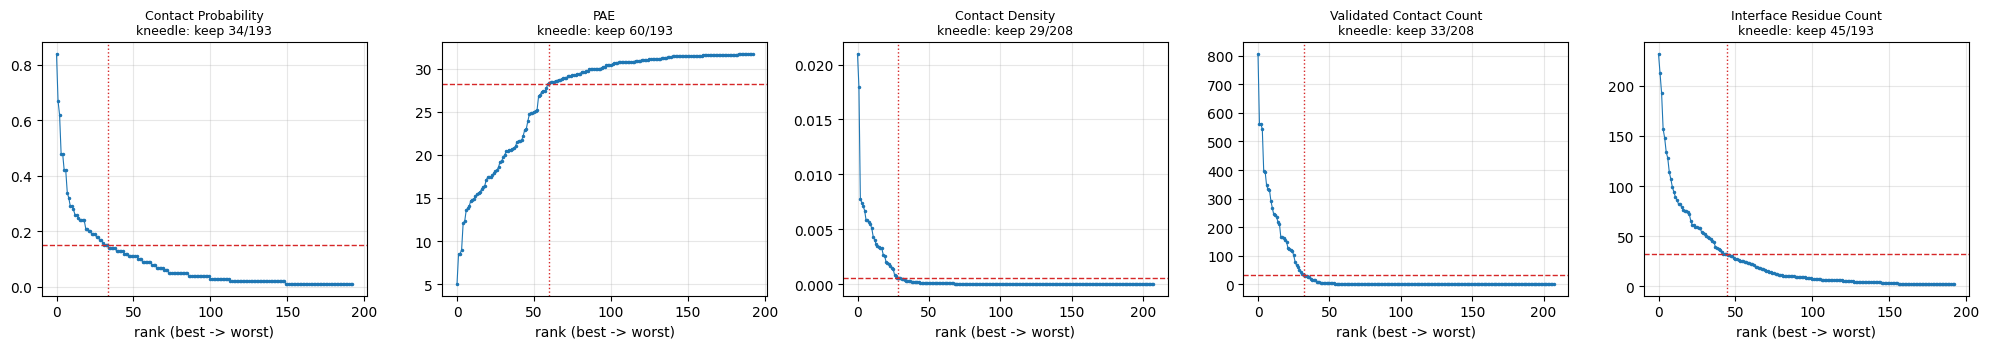


FINAL EVIDENCE GAP SELECTION
contact_probability                 → 34 candidates
pae                                 → 60 candidates
contact_density                     → 29 candidates
validated_contact_count             → 33 candidates
interface_residue_count             → 45 candidates
--------------------------------------------------------------------------------
OR / UNION candidates : 75
Input samples         : 208
Retention             : 36.06%

NEXT CELL INPUT:
EMSCORING_INPUT_RECORDS
EVIDENCE_GAP_SELECTION

No JSON or CSV intermediate file was created.
All selected sample paths are available in-memory through EMSCORING_INPUT_RECORDS.


In [9]:
# ================================================================
# EVIDENCE DISTRIBUTION + CUTOFF ANALYSIS (Kneedle elbow)
# ================================================================
#
# PURPOSE
# -------
# 208 AF3 prediction metadata files
#     ↓
# Extract 5 evidence features
#     ↓
# Sort samples within each evidence (best -> worst)
#     ↓
# Locate the elbow of the sorted-value curve (Kneedle algorithm)
#     ↓
# Keep samples at least as good as the elbow value
#   (no elbow -> previous rule: first 95th-percentile gap from the worst side)
#     ↓
# OR / UNION across all five evidence sets
#     ↓
# Produce in-memory object for next HADDOCK EMscoring cell
#
# CUTOFF_METHOD = "gap95" in section 7 restores the previous behaviour.
# Requires modules/evidence_cutoff.py.
#
# NO JSON INTERMEDIATE FILE
# NO CSV INTERMEDIATE FILE
# ================================================================

from pathlib import Path
import json
import math
import numpy as np
import pandas as pd


# ================================================================
# 1. INPUT
# ================================================================

if "records" not in globals():
    raise RuntimeError(
        "Required object 'records' was not found.\n"
        "The 208-sample metadata record list must exist before "
        "running this cell."
    )

if not isinstance(records, list):
    raise TypeError(
        f"'records' must be a list, got {type(records).__name__}"
    )

if len(records) == 0:
    raise RuntimeError("records is empty.")

print("=" * 80)
print("EVIDENCE DISTRIBUTION + GAP LOCATION ANALYSIS")
print("=" * 80)

print(f"Input records : {len(records)}")


# ================================================================
# 2. EVIDENCE POLICY
# ================================================================
#
# Five evidence features are used.
#
# HIGHER = better
# LOWER  = better
#
# CP  : Contact Probability
# PAE : Predicted Aligned Error
# CD  : Contact Density
# VCC : Validated Contact Count
# IRC : Interface Residue Count
# ================================================================

EVIDENCE_POLICY = {
    "contact_probability": {
        "label": "Contact Probability",
        "direction": "higher",
    },
    "pae": {
        "label": "PAE",
        "direction": "lower",
    },
    "contact_density": {
        "label": "Contact Density",
        "direction": "higher",
    },
    "validated_contact_count": {
        "label": "Validated Contact Count",
        "direction": "higher",
    },
    "interface_residue_count": {
        "label": "Interface Residue Count",
        "direction": "higher",
    },
}


# ================================================================
# 3. METADATA EXTRACTION
# ================================================================
#
# IMPORTANT
# ---------
# The records currently contain metadata_path, while the actual
# evidence values live inside *_evidence_metadata.json.
#
# We therefore read each metadata file directly.
#
# No new metadata files are generated.
# ================================================================

def _load_json(path):
    path = Path(path)

    if not path.is_file():
        raise FileNotFoundError(
            f"Evidence metadata file does not exist:\n{path}"
        )

    with path.open("r", encoding="utf-8") as f:
        return json.load(f)


def _safe_float(value):
    if value is None:
        return None

    try:
        value = float(value)
    except (TypeError, ValueError):
        return None

    if not math.isfinite(value):
        return None

    return value


def _extract_interface_residue_count(metadata):
    interface = metadata.get("interface_residues")

    if not isinstance(interface, dict):
        return None

    count = 0

    found_any = False

    for chain_value in interface.values():

        if isinstance(chain_value, list):
            count += len(chain_value)
            found_any = True

    return count if found_any else None


def _extract_validated_contact_count(metadata):
    contact_evidence = metadata.get("contact_evidence")

    if not isinstance(contact_evidence, dict):
        return None

    return _safe_float(
        contact_evidence.get(
            "pae_validated_pair_count"
        )
    )


def _extract_contact_probability(metadata):
    """
    Extract the representative CP from the geometry pairs.

    Current metadata schema stores per-pair CP under:

        structure_consistency
            -> geometry
                -> pairs[*]
                    -> contact_probability

    Representative value:
        maximum observed CP among geometry pairs.

    This preserves the strongest AF3 contact evidence for a
    prediction.
    """

    structure_consistency = metadata.get(
        "structure_consistency"
    )

    if not isinstance(structure_consistency, dict):
        return None

    geometry = structure_consistency.get(
        "geometry"
    )

    if not isinstance(geometry, dict):
        return None

    pairs = geometry.get("pairs")

    if not isinstance(pairs, list):
        return None

    values = []

    for pair in pairs:

        if not isinstance(pair, dict):
            continue

        value = _safe_float(
            pair.get("contact_probability")
        )

        if value is not None:
            values.append(value)

    if not values:
        return None

    return max(values)


def _extract_pae(metadata):
    """
    Extract representative PAE from geometry pairs.

    Current metadata schema stores per-pair PAE under:

        structure_consistency
            -> geometry
                -> pairs[*]
                    -> pae

    Representative value:
        minimum observed PAE.

    Lower PAE is better, so the strongest/lowest-confidence-error
    pair is retained as the prediction-level evidence.
    """

    structure_consistency = metadata.get(
        "structure_consistency"
    )

    if not isinstance(structure_consistency, dict):
        return None

    geometry = structure_consistency.get(
        "geometry"
    )

    if not isinstance(geometry, dict):
        return None

    pairs = geometry.get("pairs")

    if not isinstance(pairs, list):
        return None

    values = []

    for pair in pairs:

        if not isinstance(pair, dict):
            continue

        value = _safe_float(
            pair.get("pae")
        )

        if value is not None:
            values.append(value)

    if not values:
        return None

    return min(values)


def _extract_contact_density(metadata):
    """
    Contact density definition:

        candidate_pair_count / cross_chain_pair_count

    This normalizes the number of AF3 candidate contacts by the
    number of possible cross-chain residue pairs.
    """

    contact_evidence = metadata.get(
        "contact_evidence"
    )

    if not isinstance(contact_evidence, dict):
        return None

    candidate_count = _safe_float(
        contact_evidence.get(
            "candidate_pair_count"
        )
    )

    cross_chain_count = _safe_float(
        contact_evidence.get(
            "cross_chain_pair_count"
        )
    )

    if (
        candidate_count is None
        or cross_chain_count is None
        or cross_chain_count <= 0
    ):
        return None

    return candidate_count / cross_chain_count


def extract_five_evidence(metadata):
    """
    Convert one evidence metadata JSON into the five
    prediction-level evidence values.
    """

    return {
        "contact_probability":
            _extract_contact_probability(metadata),

        "pae":
            _extract_pae(metadata),

        "contact_density":
            _extract_contact_density(metadata),

        "validated_contact_count":
            _extract_validated_contact_count(metadata),

        "interface_residue_count":
            _extract_interface_residue_count(metadata),
    }


# ================================================================
# 4. BUILD NORMALIZED IN-MEMORY RECORDS
# ================================================================

normalized_records = []

missing_metadata = []

for record in records:

    prediction_id = record.get(
        "prediction_id"
    )

    fold_id = record.get(
        "fold_id"
    )

    metadata_path = record.get(
        "metadata_path"
    )

    if not metadata_path:
        missing_metadata.append(
            prediction_id
        )
        continue

    metadata = _load_json(
        metadata_path
    )

    evidence_values = extract_five_evidence(
        metadata
    )

    normalized_record = {
        "fold_id": fold_id,
        "prediction_id": prediction_id,
        "metadata_path": str(metadata_path),
        **evidence_values,
    }

    normalized_records.append(
        normalized_record
    )


if missing_metadata:
    raise RuntimeError(
        "Some records have no metadata_path:\n"
        + "\n".join(
            str(x)
            for x in missing_metadata
        )
    )


print(
    f"Normalized records : "
    f"{len(normalized_records)}"
)


# ================================================================
# 5. CONVERT TO DATAFRAME
# ================================================================

evidence_df = pd.DataFrame(
    normalized_records
)

if len(evidence_df) != len(records):
    raise RuntimeError(
        "Normalized record count does not match input count.\n"
        f"Input      : {len(records)}\n"
        f"Normalized : {len(evidence_df)}"
    )


# ================================================================
# 6. FEATURE COVERAGE
# ================================================================

print("\n" + "=" * 80)
print("FEATURE COVERAGE")
print("=" * 80)

coverage_rows = []

for feature in EVIDENCE_POLICY:

    available = int(
        evidence_df[feature]
        .notna()
        .sum()
    )

    total = len(evidence_df)

    coverage_rows.append({
        "evidence": feature,
        "available": available,
        "missing": total - available,
        "coverage_pct":
            100.0 * available / total
            if total
            else 0.0,
    })

coverage_df = pd.DataFrame(
    coverage_rows
)

print(
    coverage_df.to_string(
        index=False
    )
)


# ================================================================
# 7. CUTOFF ANALYSIS (Kneedle elbow; 95th-percentile gap as fallback)
# ================================================================
#
# For each evidence:
#
# 1. Remove missing values.
# 2. Orient so that larger = better (PAE is negated), optional transform.
# 3. Sort BEST -> WORST and locate the elbow of the sorted-value curve
#    with the Kneedle algorithm (largest distance to the chord after
#    normalizing rank and value to [0, 1]).
# 4. Keep every sample whose value is at least as good as the elbow
#    value -> evidence-specific candidate set.
# 5. No elbow (too few values, flat or almost straight curve):
#    fall back to the previous rule (first 95th-percentile gap from the
#    worst side) and report it.
#
# Logic: modules/evidence_cutoff.py (tested separately).
# ================================================================

import importlib
import evidence_cutoff as ec
importlib.reload(ec)

# ---------------- settings ----------------------------------------
CUTOFF_METHOD = "kneedle"     # "kneedle" | "gap95" (= previous behaviour)

# Optional transform per evidence before the elbow search
# (None or "log1p"; log1p is an option for heavy-tailed counts).
KNEEDLE_TRANSFORM = {
    "contact_probability":     None,
    "pae":                     None,
    "contact_density":         None,
    "validated_contact_count": None,
    "interface_residue_count": None,
}
KNEEDLE_MIN_POINTS   = 10     # fewer values -> fallback
KNEEDLE_MIN_DISTANCE = 0.05   # max distance to the chord below this = no elbow
BOOTSTRAP_N          = 200    # resamples for the stability report (0 = off)
PLOT_CUTOFFS         = True

print("\n" + "=" * 80)
print(f"CUTOFF METHOD: {CUTOFF_METHOD}  (evidence_cutoff {ec.MODULE_VERSION})")
print("=" * 80)

EVIDENCE_CUTOFF_RESULTS = {}

for feature, policy in EVIDENCE_POLICY.items():

    direction = policy["direction"]
    available_df = evidence_df[evidence_df[feature].notna()].reset_index(drop=True)
    values = available_df[feature].astype(float).to_numpy()
    transform = KNEEDLE_TRANSFORM.get(feature)

    print("\n" + "-" * 80)
    print(f"EVIDENCE: {policy['label']}  ({direction} is better)")
    print("-" * 80)
    print(f"Available samples   : {len(values)}")

    res = ec.select_better_side(
        values, direction,
        method=CUTOFF_METHOD,
        transform=transform,
        min_points=KNEEDLE_MIN_POINTS,
        min_distance=KNEEDLE_MIN_DISTANCE,
    )
    candidate_ids = available_df.loc[res["mask"], "prediction_id"].tolist()

    entry = {
        "status": "PASS" if res["method_used"] != "none" else "NO_CUTOFF",
        "direction": direction,
        "method_used": res["method_used"],
        "cutoff_value": res["cutoff_value"],
        "n_available": len(values),
        "candidate_count": len(candidate_ids),
        "candidate_ids": candidate_ids,
        "diagnostics": {k: v for k, v in res.items() if k != "mask"},
        "sorted_records": available_df[["fold_id", "prediction_id", feature]]
            .sort_values(feature, ascending=(direction == "lower"), kind="mergesort")
            .to_dict(orient="records"),
    }

    print(f"Method used         : {res['method_used']}")
    if res["method_used"] == "kneedle":
        print(f"Curve shape         : {res['shape']}")
        print(f"Elbow rank          : {res['knee_rank']} of {res['n']} (best = 0)")
        print(f"Chord distance      : {res['distance']:.3f}")
        if transform:
            print(f"Transform           : {transform}")
    elif res["method_used"].startswith("gap95"):
        if res["method_used"] == "gap95_fallback":
            print("NOTE                : no Kneedle elbow -> 95th-percentile gap rule")
        print(f"95th percentile gap : {res['gap_95']:.6g}")
        print(f"Primary gap         : {res['primary_gap']:.6g} at position {res['primary_gap_position']}")
    print(f"Cutoff value        : {res['cutoff_value']}")
    print(f"Better-side samples : {len(candidate_ids)}")

    if BOOTSTRAP_N and res["method_used"] == "kneedle":
        boot = ec.bootstrap_cutoff(
            values, direction, transform, n_boot=BOOTSTRAP_N,
            min_points=KNEEDLE_MIN_POINTS, min_distance=KNEEDLE_MIN_DISTANCE,
        )
        entry["bootstrap"] = boot
        print(f"Bootstrap cutoff    : p05={boot['cutoff_p05']:.6g}  "
              f"p50={boot['cutoff_p50']:.6g}  p95={boot['cutoff_p95']:.6g}  "
              f"(no elbow in {boot['no_elbow_fraction']:.0%} of {boot['n_boot']})")

    EVIDENCE_CUTOFF_RESULTS[feature] = entry

# The OR / summary sections below read EVIDENCE_GAP_RESULTS.
EVIDENCE_GAP_RESULTS = EVIDENCE_CUTOFF_RESULTS


# ------------------------------------------------------------------
# Sorted-value curves with the cutoff (best -> worst)
# ------------------------------------------------------------------
if PLOT_CUTOFFS:
    import matplotlib.pyplot as plt

    fig, axes = plt.subplots(1, len(EVIDENCE_POLICY), figsize=(4 * len(EVIDENCE_POLICY), 3.6))
    for ax, (feature, policy) in zip(np.atleast_1d(axes), EVIDENCE_POLICY.items()):
        r = EVIDENCE_CUTOFF_RESULTS[feature]
        vals = np.array([rec[feature] for rec in r["sorted_records"]], dtype=float)
        ax.plot(np.arange(len(vals)), vals, ".-", ms=3, lw=0.8)
        if r["cutoff_value"] is not None:
            ax.axhline(r["cutoff_value"], color="tab:red", ls="--", lw=1)
            ax.axvline(r["candidate_count"] - 0.5, color="tab:red", ls=":", lw=1)
        ax.set_title(f"{policy['label']}\n{r['method_used']}: keep {r['candidate_count']}/{r['n_available']}",
                     fontsize=9)
        ax.set_xlabel("rank (best -> worst)")
        ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()


# ================================================================
# 8. OR / UNION
# ================================================================
#
# IMPORTANT:
#
# Evidence-specific candidate sets are combined using OR.
#
# A sample only needs to satisfy the better-side criterion for
# ONE of the five evidence features to enter the EMscoring pool.
# ================================================================

candidate_membership = {}

for feature, result in EVIDENCE_GAP_RESULTS.items():

    for prediction_id in result.get(
        "candidate_ids",
        []
    ):

        if prediction_id not in candidate_membership:

            candidate_membership[
                prediction_id
            ] = []

        candidate_membership[
            prediction_id
        ].append(feature)


OR_CANDIDATE_IDS = sorted(
    candidate_membership.keys()
)


# ================================================================
# 9. BUILD FINAL EMscoring INPUT OBJECT
# ================================================================
#
# Each selected sample receives:
#
# - fold_id
# - prediction_id
# - metadata_path
# - evidence values
# - which evidence(s) selected it
#
# This object is passed directly to the next cell.
# ================================================================

record_lookup = {
    r["prediction_id"]: r
    for r in normalized_records
}

EMSCORING_INPUT_RECORDS = []

for prediction_id in OR_CANDIDATE_IDS:

    base_record = dict(
        record_lookup[
            prediction_id
        ]
    )

    base_record[
        "selected_by_evidence"
    ] = candidate_membership[
        prediction_id
    ]

    base_record[
        "selection_count"
    ] = len(
        candidate_membership[
            prediction_id
        ]
    )

    EMSCORING_INPUT_RECORDS.append(
        base_record
    )


# ================================================================
# 10. FINAL IN-MEMORY OBJECT
# ================================================================

EVIDENCE_GAP_SELECTION = {

    "input_count":
        len(records),

    "evidence_count":
        len(EVIDENCE_POLICY),

    "evidence_policy":
        EVIDENCE_POLICY,

    "feature_coverage":
        coverage_df.to_dict(
            orient="records"
        ),

    "evidence_results":
        EVIDENCE_GAP_RESULTS,

    "or_candidate_ids":
        OR_CANDIDATE_IDS,

    "candidate_membership":
        candidate_membership,

    "emscoring_input":
        EMSCORING_INPUT_RECORDS,
}


# ================================================================
# 11. FINAL SUMMARY
# ================================================================

print("\n" + "=" * 80)
print("FINAL EVIDENCE GAP SELECTION")
print("=" * 80)

for feature in EVIDENCE_POLICY:

    result = EVIDENCE_GAP_RESULTS.get(
        feature,
        {}
    )

    print(
        f"{feature:35s} "
        f"→ "
        f"{len(result.get('candidate_ids', []))}"
        f" candidates"
    )

print("-" * 80)

print(
    f"OR / UNION candidates : "
    f"{len(OR_CANDIDATE_IDS)}"
)

print(
    f"Input samples         : "
    f"{len(records)}"
)

print(
    f"Retention             : "
    f"{100.0 * len(OR_CANDIDATE_IDS) / len(records):.2f}%"
)

print("=" * 80)

print(
    "\nNEXT CELL INPUT:"
)

print(
    "EMSCORING_INPUT_RECORDS"
)

print(
    "EVIDENCE_GAP_SELECTION"
)

print(
    "\nNo JSON or CSV intermediate file was created."
)

print(
    "All selected sample paths are available in-memory "
    "through EMSCORING_INPUT_RECORDS."
)

print("=" * 80)

## 6. Scoring inputs (shared by EMscoring and OpenMM)

Resolves every `OR_CANDIDATE_IDS` entry **through `SAMPLES`** and the
`SCORING_INPUT_SOURCE` switch, so both scorers receive identical PDBs.
v2 guessed `fold_xxx_model_0.pdb`; folds whose PDB has another model index
were silently dropped from EMscoring (63 of 76 candidates ran).

In [10]:
# ============================================================
# SCORING INPUTS
# ============================================================
if "OR_CANDIDATE_IDS" not in globals():
    raise RuntimeError("OR_CANDIDATE_IDS missing — run the gap-selection cell first.")

PDB_KEY = {"structure": "input_pdb", "haddock_ready": "haddock_ready_pdb"}
if SCORING_INPUT_SOURCE not in PDB_KEY:
    raise ValueError(f"SCORING_INPUT_SOURCE must be one of {list(PDB_KEY)}")

SCORING_INPUTS, SCORING_EXCLUDED = [], []

for prediction_id in OR_CANDIDATE_IDS:
    prediction_id = str(prediction_id)
    fold_id = fold_of(prediction_id)
    sample = SAMPLES.get(fold_id)

    if sample is None:
        SCORING_EXCLUDED.append((prediction_id, "fold not in SAMPLES"))
        continue
    known = sample.get("prediction_id")
    if known is not None and known != prediction_id:
        SCORING_EXCLUDED.append((prediction_id, f"prediction_id mismatch ({known})"))
        continue

    pdb = sample.get(PDB_KEY[SCORING_INPUT_SOURCE])
    if pdb is None or not Path(pdb).is_file():
        SCORING_EXCLUDED.append((prediction_id, f"no {PDB_KEY[SCORING_INPUT_SOURCE]} on disk"))
        continue

    SCORING_INPUTS.append({
        "prediction_id": prediction_id,
        "fold_id": fold_id,
        "pdb_path": str(pdb),
    })

print("=" * 80)
print("SCORING INPUTS")
print("=" * 80)
print("Source     :", SCORING_INPUT_SOURCE)
print("Candidates :", len(OR_CANDIDATE_IDS))
print("Resolved   :", len(SCORING_INPUTS))
print("Excluded   :", len(SCORING_EXCLUDED))
for pid, why in SCORING_EXCLUDED:
    print(f"  - {pid}: {why}")

if not SCORING_INPUTS:
    raise RuntimeError("No scoring inputs were resolved.")

SCORING INPUTS
Source     : structure
Candidates : 75
Resolved   : 75
Excluded   : 0


## 7. HADDOCK3 EMscoring (topoaa → emscoring, no docking)

In [11]:
# ============================================================
# HADDOCK EMscoring
# ============================================================
import haddock_emscoring
importlib.reload(haddock_emscoring)

print("MODULE :", haddock_emscoring.__file__, "| version", haddock_emscoring.MODULE_VERSION)

valid, invalid = [], []
for item in SCORING_INPUTS:
    check = haddock_emscoring.validate_emscoring_pdb(
        item["pdb_path"], expected_chains=tuple(EXPECTED_CHAINS)
    )
    (valid if check["status"] == "PASS" else invalid).append({**item, "validation": check})

print(f"Pre-flight  VALID: {len(valid)}  INVALID: {len(invalid)}")
for item in invalid:
    print("  INVALID", item["prediction_id"], "-", item["validation"].get("reason"))
if not valid:
    raise RuntimeError("All selected samples failed PDB pre-flight validation.")

EM_OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
RESULTS_CSV = EM_OUTPUT_ROOT / "haddock_emscoring_results.csv"

em_results = haddock_emscoring.batch_emscoring(
    records=[{k: v for k, v in x.items() if k != "validation"} for x in valid],
    output_root=EM_OUTPUT_ROOT,
    ncores=EM_NCORES,
    nemsteps=EM_NEMSTEPS,
    haddock_executable=HADDOCK_EXECUTABLE,
    skip_completed=True,
    results_csv=RESULTS_CSV,
)

print("\n" + "=" * 80)
print("HADDOCK EMscoring SUMMARY")
print("=" * 80)
for key, value in haddock_emscoring.summarize_emscoring(em_results).items():
    print(f"{key:22s}: {value}")

scored = sorted(
    (r for r in em_results if r.status in ("SUCCESS", "SKIPPED") and r.haddock_score is not None),
    key=lambda r: r.haddock_score,
)
print(f"\nScored: {len(scored)} / {len(em_results)}   CSV: {RESULTS_CSV}")
for rank, r in enumerate(scored[:20], start=1):
    print(f"{rank:4d}  {r.haddock_score:12.3f}  {r.prediction_id}")
if len(scored) > 20:
    print(f"... {len(scored) - 20} more (see CSV)")

MODULE : /content/drive/MyDrive/AF3_HADDOCK/modules/haddock_emscoring.py | version 1.0.0
Pre-flight  VALID: 75  INVALID: 0

HADDOCK EMscoring 1
Prediction ID: fold_004_deguysxt_cds_0005_hpiihm_00268
Input PDB: /content/drive/MyDrive/MD_output_pdb/fold_004/fold_004_model_0.pdb
Status: SKIPPED
HADDOCK score: 60.785

HADDOCK EMscoring 2
Prediction ID: fold_013_deguysxt_cds_0005_hpiihm_01676
Input PDB: /content/drive/MyDrive/MD_output_pdb/fold_013/fold_013_model_0.pdb
Status: SKIPPED
HADDOCK score: -66.782

HADDOCK EMscoring 3
Prediction ID: fold_014_deguysxt_cds_0005_hpiihm_01689
Input PDB: /content/drive/MyDrive/MD_output_pdb/fold_014/fold_014_model_1.pdb
Status: SKIPPED
HADDOCK score: -24.927

HADDOCK EMscoring 4
Prediction ID: fold_033_deguysxt_cds_0005_hpiihm_03698
Input PDB: /content/drive/MyDrive/MD_output_pdb/fold_033/fold_033_model_0.pdb
Status: SKIPPED
HADDOCK score: -19.28

HADDOCK EMscoring 5
Prediction ID: fold_034_deguysxt_cds_0005_hpiihm_03725
Input PDB: /content/drive/MyDri

## 8. OpenMM + CHARMM scoring

`openmm_charmm_scoring.py` **v1.2.0 is required** (adds DCD output) (replace the file in
`AF3_HADDOCK/modules/`). v1.0.0 called `CharmmParameterSet.createSystem()`,
which does not exist, so all 76 samples failed.

* `OPENMM_METHOD="forcefield"` – OpenMM `charmm36.xml`; no PSF/VMD needed.
* `OPENMM_METHOD="psf"` – CHARMM rtf/prm + PSF from `MD_output_openmm/psf/`.

DCD (`OPENMM_SAVE_DCD`): `trajectories/<id>.dcd` + `pdb/<id>_minimized.pdb`
(the DCD has no topology; the PDB holds the exact simulated atoms, including
added hydrogens).

In [12]:
# ============================================================
# CHARMM FILES / PSF CHECK
# ============================================================
if OPENMM_METHOD == "psf":
    for path in (CHARMM_TOPOLOGY, CHARMM_PARAMETER):
        if not path.is_file():
            raise FileNotFoundError(
                f"Missing CHARMM file: {path}\n"
                "Place the CHARMM36m toppar files there (they are not downloaded automatically)."
            )
    print("CHARMM rtf/prm : PASS")
else:
    print(f"OPENMM_METHOD={OPENMM_METHOD!r}: rtf/prm are not used "
          "(OpenMM's bundled charmm36.xml is applied).")

OPENMM_METHOD='forcefield': rtf/prm are not used (OpenMM's bundled charmm36.xml is applied).


In [13]:
# ============================================================
# OPENMM CANDIDATES
# ============================================================
PSF_DIR     = OPENMM_ROOT / "psf"
PSF_PDB_DIR = OPENMM_ROOT / "psf_pdb"

OPENMM_CANDIDATES, OPENMM_EXCLUDED = [], []

for item in SCORING_INPUTS:
    record = dict(item, input_pdb=item["pdb_path"])
    pid = item["prediction_id"]

    if OPENMM_METHOD == "psf":
        psf, psf_pdb = PSF_DIR / f"{pid}.psf", PSF_PDB_DIR / f"{pid}.pdb"
        if not psf.is_file():
            OPENMM_EXCLUDED.append((pid, f"PSF not found: {psf.name}"))
            continue
        record["psf_path"] = str(psf)
        if psf_pdb.is_file():
            record["psf_pdb_path"] = str(psf_pdb)

    OPENMM_CANDIDATES.append(record)

print("OpenMM candidates:", len(OPENMM_CANDIDATES), "| excluded:", len(OPENMM_EXCLUDED))
for pid, why in OPENMM_EXCLUDED:
    print(f"  - {pid}: {why}")
if not OPENMM_CANDIDATES:
    raise RuntimeError("No OpenMM candidates available.")
print("First:", OPENMM_CANDIDATES[0])

OpenMM candidates: 75 | excluded: 0
First: {'prediction_id': 'fold_004_deguysxt_cds_0005_hpiihm_00268', 'fold_id': 'fold_004', 'pdb_path': '/content/drive/MyDrive/MD_output_pdb/fold_004/fold_004_model_0.pdb', 'input_pdb': '/content/drive/MyDrive/MD_output_pdb/fold_004/fold_004_model_0.pdb'}


In [14]:
# ============================================================
# OPENMM + CHARMM EXECUTION
# ============================================================
from collections import Counter
import openmm_charmm_scoring
importlib.reload(openmm_charmm_scoring)
from openmm_charmm_scoring import run_openmm_charmm_batch, summarize_openmm

OPENMM_RESULTS_DIR = OPENMM_ROOT / "results"
OPENMM_TRAJ_DIR    = OPENMM_ROOT / "trajectories"   # <prediction_id>.dcd
OPENMM_PDB_DIR     = OPENMM_ROOT / "pdb"            # <prediction_id>_minimized.pdb (DCD topology)

print("MODULE:", openmm_charmm_scoring.__file__, "| version", openmm_charmm_scoring.MODULE_VERSION)
if not openmm_charmm_scoring.MODULE_VERSION.startswith(("1.2", "1.3", "2.")):
    raise RuntimeError("Outdated openmm_charmm_scoring.py — copy v1.2.0 to the modules folder.")

openmm_results = run_openmm_charmm_batch(
    candidate_object=OPENMM_CANDIDATES,
    topology_files=[CHARMM_TOPOLOGY] if OPENMM_METHOD == "psf" else [],
    parameter_files=[CHARMM_PARAMETER] if OPENMM_METHOD == "psf" else [],
    method=OPENMM_METHOD,
    platform=OPENMM_PLATFORM,
    minimize=OPENMM_MINIMIZE,
    max_iterations=OPENMM_MAX_ITER,
    skip_completed=True,
    results_dir=OPENMM_RESULTS_DIR,
    trajectory_dir=OPENMM_TRAJ_DIR if OPENMM_SAVE_DCD else None,
    pdb_dir=OPENMM_PDB_DIR if OPENMM_SAVE_DCD else None,
    md_steps=OPENMM_MD_STEPS,
    report_interval=OPENMM_REPORT_INTERVAL,
    temperature_kelvin=OPENMM_TEMPERATURE,
)

summary = summarize_openmm(openmm_results)
print("\n" + "=" * 80)
print("OPENMM + CHARMM SUMMARY:", summary)
print("Platforms used:", dict(Counter(r["platform"] for r in openmm_results)))
if OPENMM_SAVE_DCD:
    n_dcd = sum(bool(r.get("dcd_path")) and Path(r["dcd_path"]).is_file() for r in openmm_results)
    print(f"DCD files: {n_dcd}/{len(openmm_results)}  ->  {OPENMM_TRAJ_DIR}")
    print("Load with: mdtraj.load_dcd(<dcd>, top=<_minimized.pdb>)  (pip install mdtraj)")
errors = Counter(r["error"].split(":")[0] + ": " + r["error"].split(":", 1)[-1][:80]
                 for r in openmm_results if r["status"] != "PASS")
for msg, n in errors.most_common(5):
    print(f"  {n:3d} x {msg}")
print("=" * 80)

if summary["pass"] == 0:
    raise RuntimeError("OpenMM scoring failed for every sample — see messages above.")

MODULE: /content/drive/MyDrive/AF3_HADDOCK/modules/openmm_charmm_scoring.py | version 1.2.0
[1/75] fold_004_deguysxt_cds_0005_hpiihm_00268
  status   : SKIPPED (cached PASS)
[2/75] fold_013_deguysxt_cds_0005_hpiihm_01676
  status   : SKIPPED (cached PASS)
[3/75] fold_014_deguysxt_cds_0005_hpiihm_01689
  status   : SKIPPED (cached PASS)
[4/75] fold_033_deguysxt_cds_0005_hpiihm_03698
  status   : SKIPPED (cached PASS)
[5/75] fold_034_deguysxt_cds_0005_hpiihm_03725
  status   : SKIPPED (cached PASS)
[6/75] fold_036_deguysxt_cds_0005_hpiihm_03928
  status   : PASS
  platform : OpenCL | method: forcefield
  initial  : 181.386 kJ/mol
  minimized: -158114.896 kJ/mol
  dcd      : /content/drive/MyDrive/MD_output_openmm/trajectories/fold_036_deguysxt_cds_0005_hpiihm_03928.dcd (2 frames)
[7/75] fold_040_deguysxt_cds_0005_hpiihm_04320
  status   : SKIPPED (cached PASS)
[8/75] fold_044_deguysxt_cds_0005_hpiihm_04357
  status   : SKIPPED (cached PASS)
[9/75] fold_045_deguysxt_cds_0005_hpiihm_04358


## 9. Merged table (EMscoring + OpenMM)

In [15]:
# ============================================================
# MERGED RESULT TABLE
# ============================================================
import pandas as pd
from dataclasses import asdict

em_df = pd.DataFrame([asdict(r) for r in em_results])[
    ["prediction_id", "status", "haddock_score", "evdw", "eelec", "edesolv", "bsa"]
].rename(columns={"status": "em_status"})

mm_df = pd.DataFrame(openmm_results)[
    ["prediction_id", "status", "method", "platform",
     "initial_potential_kj_mol", "minimized_potential_kj_mol", "n_atoms",
     "dcd_path", "topology_pdb"]
].rename(columns={"status": "openmm_status"})

merged = em_df.merge(mm_df, on="prediction_id", how="outer")
merged.insert(0, "fold_id", merged["prediction_id"].astype(str).str[:8])
merged = merged.sort_values("haddock_score")

MERGED_CSV = OPENMM_RESULTS_DIR / "em_openmm_merged.csv"
merged.to_csv(MERGED_CSV, index=False)
print("Saved:", MERGED_CSV, "| rows:", len(merged))
merged.head(20)

Saved: /content/drive/MyDrive/MD_output_openmm/results/em_openmm_merged.csv | rows: 75


,fold_id,prediction_id,em_status,haddock_score,evdw,eelec,edesolv,bsa,openmm_status,method,platform,initial_potential_kj_mol,minimized_potential_kj_mol,n_atoms,dcd_path,topology_pdb
62,fold_192,fold_192_deguysxt_cds_0009_hpiihm_03928,SKIPPED,-427.484,None,None,None,None,PASS,forcefield,OpenCL,-7.178891e+03,-81406.148891,14841,/content/drive/MyDrive/MD_output_openmm/trajec...,/content/drive/MyDrive/MD_output_openmm/pdb/fo...
26,fold_140,fold_140_deguysxt_cds_0008_hpiihm_03928,SKIPPED,-303.274,None,None,None,None,PASS,forcefield,OpenCL,1.315814e+06,-175352.706267,35106,/content/drive/MyDrive/MD_output_openmm/trajec...,/content/drive/MyDrive/MD_output_openmm/pdb/fo...
65,fold_195,fold_195_deguysxt_cds_0009_hpiihm_04206,SKIPPED,-271.803,None,None,None,None,PASS,forcefield,OpenCL,1.174004e+08,-91560.750816,15239,/content/drive/MyDrive/MD_output_openmm/trajec...,/content/drive/MyDrive/MD_output_openmm/pdb/fo...
64,fold_194,fold_194_deguysxt_cds_0009_hpiihm_04063,SKIPPED,-257.463,None,None,None,None,PASS,forcefield,OpenCL,-6.329813e+03,-37917.721610,9044,/content/drive/MyDrive/MD_output_openmm/trajec...,/content/drive/MyDrive/MD_output_openmm/pdb/fo...
41,fold_171,fold_171_deguysxt_cds_0009_hpiihm_01693,SKIPPED,-184.938,None,None,None,None,PASS,forcefield,OpenCL,-1.255375e+04,-49466.849992,9968,/content/drive/MyDrive/MD_output_openmm/trajec...,/content/drive/MyDrive/MD_output_openmm/pdb/fo...
34,fold_163,fold_163_deguysxt_cds_0009_hpiihm_00931,SKIPPED,-180.780,None,None,None,None,PASS,forcefield,OpenCL,-2.802390e+04,-49037.084486,9033,/content/drive/MyDrive/MD_output_openmm/trajec...,/content/drive/MyDrive/MD_output_openmm/pdb/fo...
61,fold_191,fold_191_deguysxt_cds_0009_hpiihm_03803,SKIPPED,-171.257,None,None,None,None,PASS,forcefield,OpenCL,-3.945547e+04,-87047.510645,13983,/content/drive/MyDrive/MD_output_openmm/trajec...,/content/drive/MyDrive/MD_output_openmm/pdb/fo...
55,fold_185,fold_185_deguysxt_cds_0009_hpiihm_03300,SKIPPED,-161.765,None,None,None,None,PASS,forcefield,OpenCL,2.545625e+05,-60710.141746,13744,/content/drive/MyDrive/MD_output_openmm/trajec...,/content/drive/MyDrive/MD_output_openmm/pdb/fo...
74,fold_208,fold_208_deguysxt_cds_0009_hpiihm_05368,SKIPPED,-154.325,None,None,None,None,PASS,forcefield,OpenCL,1.780901e+05,-39869.054968,7231,/content/drive/MyDrive/MD_output_openmm/trajec...,/content/drive/MyDrive/MD_output_openmm/pdb/fo...
40,fold_170,fold_170_deguysxt_cds_0009_hpiihm_01689,SKIPPED,-151.045,None,None,None,None,PASS,forcefield,OpenCL,-2.696559e+04,-52143.633306,9624,/content/drive/MyDrive/MD_output_openmm/trajec...,/content/drive/MyDrive/MD_output_openmm/pdb/fo...


## 10. Finalize

Copies the final tables to `outputs/pipeline/` (kept after cleanup) and marks
the pipeline stage as done. Then run the DCD viewer notebook; its last cell
removes the intermediates.

In [ ]:
# ============================================================
# FINALIZE: final tables -> outputs/pipeline, mark stage
# ============================================================
import pandas as pd

_needed = ["SAMPLES", "evidence_df", "EVIDENCE_GAP_RESULTS", "EMSCORING_INPUT_RECORDS",
           "OR_CANDIDATE_IDS", "merged", "MERGED_CSV", "RESULTS_CSV", "OPENMM_RESULTS_DIR"]
_missing = [n for n in _needed if n not in globals()]
if _missing:
    raise RuntimeError(f"Run the pipeline cells first (missing: {_missing}).")

out = L.outputs_pipeline
out.mkdir(parents=True, exist_ok=True)

copied = pl.collect_files(
    [MERGED_CSV, RESULTS_CSV, OPENMM_RESULTS_DIR / "openmm_charmm_results.csv"], out
)

evidence_df.to_csv(out / "evidence_values.csv", index=False)
pd.DataFrame([
    {"evidence": f, "method_used": r.get("method_used"), "cutoff_value": r.get("cutoff_value"),
     "n_available": r.get("n_available"), "candidate_count": r.get("candidate_count")}
    for f, r in EVIDENCE_GAP_RESULTS.items()
]).to_csv(out / "evidence_cutoffs.csv", index=False)
pd.DataFrame(EMSCORING_INPUT_RECORDS).to_csv(out / "evidence_candidates.csv", index=False)
pd.DataFrame([
    {"fold_id": f, "prediction_id": s.get("prediction_id"),
     "input_pdb": str(s.get("input_pdb", "")), "haddock_ready_pdb": str(s.get("haddock_ready_pdb", "")),
     "step2_status": s.get("step2_status"), "downstream_action": s.get("downstream_action")}
    for f, s in sorted(SAMPLES.items())
]).to_csv(out / "samples.csv", index=False)

pl.mark_stage(L, "pipeline", samples=len(SAMPLES), candidates=len(OR_CANDIDATE_IDS),
              merged_rows=len(merged))

print("Final tables:", out)
for f in sorted(out.iterdir()):
    print("  ", f.name)
print("Stage 'pipeline' marked done ->", L.status_file)
print("Next: DCD viewer notebook (same DATASET).")